# Домашнее задание: Hugging Face Transformers

## Часть 1. Самостоятельный разбор туториалов

## 1. Text classification task guide

В туториале показывают, как дообучить (зафайнтюнить) модель для классификации текстов. Сначала загружаем датасет через load_dataset, затем токенизируем его, переводим в числовые значения для модели, через модуль Trainer проводим обучение, через функцию compute_metrics, которую мы передаем в Trainer, считаем метрики качества (accuracy, f1_macro).

Критичные для классификации текста параметры:

1. num_labels – число классов для различения
2. learning_rate – размер шага при обновлении весов
3. per_device_train_batch_size – сколько примеров модель обрабатывает за раз
4. num_train_epochs – количество эпох обучения
5. weight_decay – ограничиваем переобучение
6. problem_type (single/multi) – у каждого текста одна/несколько эталонных меток


**Фрагмент кода с инициализацией модели (в том числе):**

```python
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased", num_labels=2, id2label=id2label, label2id=label2id
)
```
Загружаем предобученный DistilBERT, донастраиваем для нашей задачи классификации.

## 2. Trainer documentation

В TrainingArguments задаем основные настройки обучения: скорость, размер батча, число эпох, частоту проверки и сохранения модели. В compute_metrics считаем метрики качества на валидационной выборке. EarlyStoppingCallback позволяет предотвратить переобучение, если выбранная метрика перестает улучшаться.

**Фрагмент кода, составленных по структуре из документации:**

```python
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset['train'],
    eval_dataset=tokenized_dataset['validation'],
    processing_class=tok,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)
```

## 3. Datasets: load local CSV/JSON

Функция load_dataset загружает данные из csv/json в объект формата Dataset. В data_files можно задать путь к файлам и назначить обучающую, валидационную и тестовую выборки.

**Фрагмент кода из документации:**

```python
from datasets import load_dataset
dataset = load_dataset("lhoestq/demo1")
```


## 4. Evaluate: F1 metric

F1 объединяет precision и recall в один показатель.
Micro — суммирует результаты определения всех классов, потом считает общую метрику, поэтому более чувствительна к превалирующим в выборке классам.
Macro – считает F1 отдельно по каждому классу и усредняет значения, у каждого класса одинаковый вес вне зависимости от выраженности.
Weighted – считает F1 отдельно по каждому классу и усредняет значения в зависимости от доли в выборке — присваивает больший вес наиболее выраженному классу и наоборот.

В нашем случае ориентируемся на macro f1.

**Фрагмент кода из туториала:**

```python
import evaluate
accuracy = evaluate.load("accuracy")
```

## Проверка понимания

**1. Чем `problem_type="single_label_classification"` отличается от `"multi_label_classification"` с точки зрения функции потерь?**

Single — у объекта один правильный лейбл, multi — несколько правильных лейблов. В первом случае, чем более модель уверена в правильной метке, тем меньше ее потеря. В этом случаее используется CrossEntropyLoss: классы конкурируют между собой. В многоклассовой классификации учитывается не только неуверенность в правильном лейбле, но и, например, отсутствие второй правильной метки или, наоборот, присутствие в ответе неправильной метки — используется BCEWithLogitsLoss: для каждого класса отдельно оценивается, присутствует он или нет.


**2. Зачем нужен `processing_class=tok` в `Trainer`?**

Он передаёт Trainer токенизатор для подготовки и дополнения текстов в батчах, этот токенизатор сохраняется вместе с моделью и может использоваться при повторных загрузках без потери информации.


**3. Что будет, если не передать `compute_metrics` в `Trainer`?**

Модель будет обучаться, но метрики качества считаться не будут — мы не сможем отследить полный результат обучения, только validation loss.

# Часть 2. Практическая работа. Классификация эмоций (DistilBERT)

## 1. Установка библиотек

In [1]:
%pip install -q transformers datasets evaluate accelerate scikit-learn pandas matplotlib seaborn

## 2. Импорты и настройки

In [2]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import evaluate
import torch

from collections import Counter
from datasets import load_dataset
from sklearn.metrics import confusion_matrix, classification_report
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    set_seed
)

SEED = 42
set_seed(SEED)

MODEL_NAME = 'distilbert/distilbert-base-uncased'
MAX_LENGTH = 128
NUM_EPOCHS = 5
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 16

print('Устройство:', 'cuda' if torch.cuda.is_available() else 'cpu')

Устройство: cpu


## 3. Загрузка GoEmotions

In [3]:
dataset = load_dataset('google-research-datasets/go_emotions', 'simplified')

print(dataset)
print('Пример:', dataset['train'][0])

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})
Пример: {'text': "My favourite food is anything I didn't have to cook myself.", 'labels': [27], 'id': 'eebbqej'}


## 4. Выбранные эмоции

In [4]:
selected_emotions = [
    'admiration', 'love', 'joy', 'realization',
    'anger', 'sadness', 'grief'
]

label_names = dataset['train'].features['labels'].feature.names
label2id = {label: index for index, label in enumerate(selected_emotions)}
id2label = {index: label for label, index in label2id.items()}
selected_label_ids = [label_names.index(label) for label in selected_emotions]

print('Исходные метки:', label_names)
print('Выбранные классы:', selected_emotions)

Исходные метки: ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']
Выбранные классы: ['admiration', 'love', 'joy', 'realization', 'anger', 'sadness', 'grief']


## 5. Отбор комментариев с одной выбранной эмоцией

In [5]:
selected_dataset = dataset.filter(
    lambda example: len([
        label for label in example['labels']
        if label in selected_label_ids
    ]) == 1
)

selected_dataset = selected_dataset.map(
    lambda example: {
        'label': label2id[
            label_names[next(
                label for label in example['labels']
                if label in selected_label_ids
            )]
        ]
    }
)

print('Размеры после отбора:', selected_dataset)

Filter:   0%|          | 0/43410 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5426 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5427 [00:00<?, ? examples/s]

Map:   0%|          | 0/10615 [00:00<?, ? examples/s]

Map:   0%|          | 0/1250 [00:00<?, ? examples/s]

Map:   0%|          | 0/1278 [00:00<?, ? examples/s]

Размеры после отбора: DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id', 'label'],
        num_rows: 10615
    })
    validation: Dataset({
        features: ['text', 'labels', 'id', 'label'],
        num_rows: 1250
    })
    test: Dataset({
        features: ['text', 'labels', 'id', 'label'],
        num_rows: 1278
    })
})


## 6. Проверка распределения классов

,train,validation,test
Эмоция,,,
admiration,3757,444,462
love,1797,217,204
joy,1233,149,138
realization,1017,114,134
anger,1530,186,194
sadness,1227,131,144
grief,54,9,2


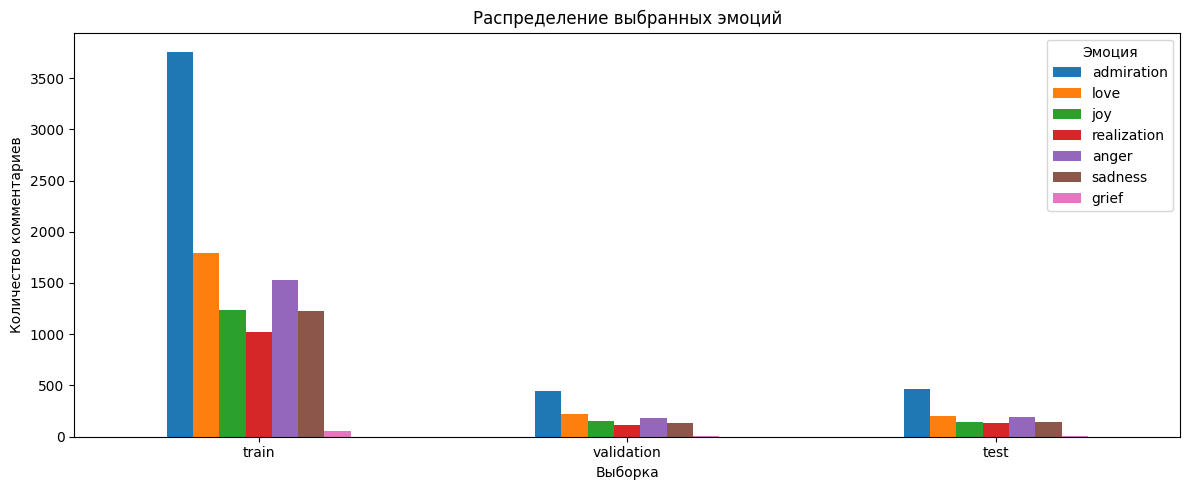

In [6]:
class_counts = {}

for split in ['train', 'validation', 'test']:
    counts = Counter(selected_dataset[split]['label'])
    class_counts[split] = [counts.get(i, 0) for i in range(len(selected_emotions))]

counts_table = pd.DataFrame(class_counts, index=selected_emotions)
counts_table.index.name = 'Эмоция'
display(counts_table)

counts_table.T.plot(kind='bar', figsize=(12, 5))
plt.xlabel('Выборка')
plt.ylabel('Количество комментариев')
plt.title('Распределение выбранных эмоций')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Примеры текстов

In [7]:
for label_id, emotion in enumerate(selected_emotions):
    example_id = selected_dataset['train']['label'].index(label_id)
    print(f'[{emotion}] {selected_dataset["train"][example_id]["text"]}')

[admiration] Damn youtube and outrage drama is super lucrative for reddit
[love] Thanks! I love watching him every week
[joy] Happy to be able to help.
[realization] Maybe that’s what happened to the great white at Houston zoo
[anger] WHY THE FUCK IS BAYLESS ISOING
[sadness] Pretty sure I’ve seen this. He swings away with the harness he is wearing. Still looks painful but I think he lives
[grief] I read on a different post that he died shortly after of internal injuries.


## 8. Токенизация

In [9]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tok(
        examples['text'],
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized_dataset = selected_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=['text', 'labels', 'id']
)

data_collator = DataCollatorWithPadding(tokenizer=tok)

print(tokenized_dataset)

Map:   0%|          | 0/10615 [00:00<?, ? examples/s]

Map:   0%|          | 0/1250 [00:00<?, ? examples/s]

Map:   0%|          | 0/1278 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 10615
    })
    validation: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1250
    })
    test: Dataset({
        features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1278
    })
})


## 9. Метрики

In [10]:
accuracy_metric = evaluate.load('accuracy')
f1_metric = evaluate.load('f1')

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)

    accuracy = accuracy_metric.compute(
        predictions=predictions,
        references=labels
    )['accuracy']

    f1_macro = f1_metric.compute(
        predictions=predictions,
        references=labels,
        average='macro'
    )['f1']

    return {
        'accuracy': accuracy,
        'f1_macro': f1_macro
    }

## 10. Модель и параметры обучения

In [11]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(selected_emotions),
    id2label=id2label,
    label2id=label2id,
    problem_type='single_label_classification'
)

training_args = TrainingArguments(
    output_dir='./distilbert_go_emotions_7',
    learning_rate=2e-5,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    num_train_epochs=NUM_EPOCHS,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',
    greater_is_better=True,
    save_total_limit=2,
    report_to='none',
    seed=SEED
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset['train'],
    eval_dataset=tokenized_dataset['validation'],
    processing_class=tok,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

print('Классов:', model.config.num_labels)
print('Модель:', MODEL_NAME)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Классов: 7
Модель: distilbert/distilbert-base-uncased


## 11. Обучение

Я случайно повторно тыкнула на 13 ячейку, поэтому вывод корявый(

In [13]:
train_result = trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 

Соединение прервалось, запускаю модель с момента последнего сохранения

In [14]:
trainer.train(resume_from_checkpoint=True)

Epoch,Training Loss,Validation Loss


TrainOutput(global_step=3320, training_loss=0.0, metrics={'train_runtime': 0.0008, 'train_samples_per_second': 0.0, 'train_steps_per_second': 0.0, 'total_flos': 466721412344370.0, 'train_loss': 0.0, 'epoch': 5.0})

## 12. Итоговые метрики на тестовой выборке

In [18]:
test_results = trainer.evaluate(
    eval_dataset=tokenized_dataset['test'],
    metric_key_prefix='test'
)

results_table = pd.DataFrame([{
    'eval_accuracy': test_results['test_accuracy'],
    'eval_f1_macro': test_results['test_f1_macro'],
    'eval_loss': test_results['test_loss']
}])

display(results_table.round(4))

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


[transformers] early stopping required metric_for_best_model, but did not find eval_f1_macro so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.183708,0.592208,5,0.841941,0.703029


,eval_accuracy,eval_f1_macro,eval_loss
0,0.8419,0.703,0.5922


## 13. Матрица ошибок

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


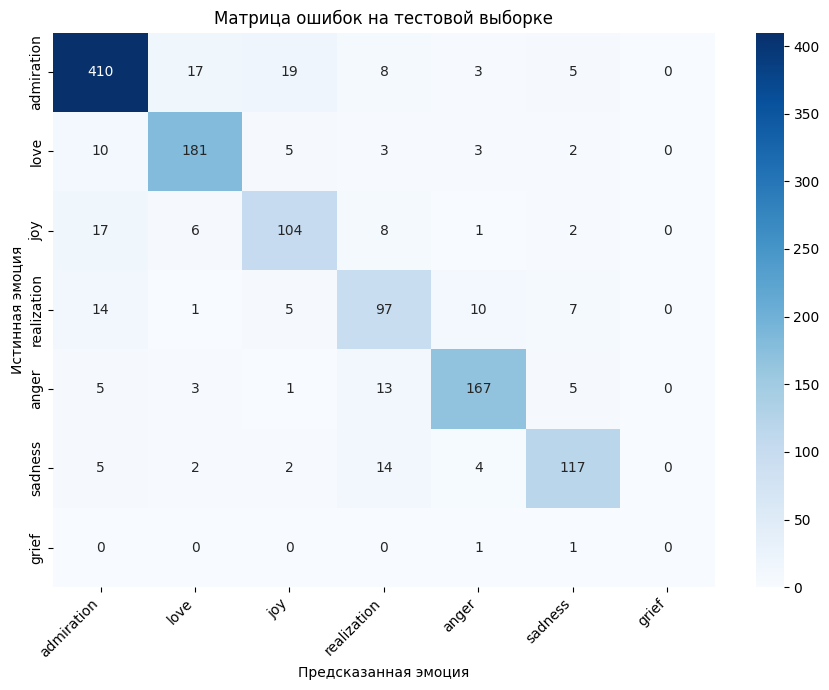

In [19]:
test_output = trainer.predict(tokenized_dataset['test'])
test_predictions = np.argmax(test_output.predictions, axis=1)
test_labels = test_output.label_ids

cm = confusion_matrix(
    test_labels,
    test_predictions,
    labels=list(range(len(selected_emotions)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=selected_emotions,
    yticklabels=selected_emotions
)
plt.xlabel('Предсказанная эмоция')
plt.ylabel('Истинная эмоция')
plt.title('Матрица ошибок на тестовой выборке')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 14. Отчет по классам

In [20]:
print(classification_report(
    test_labels,
    test_predictions,
    labels=list(range(len(selected_emotions))),
    target_names=selected_emotions,
    zero_division=0
))

              precision    recall  f1-score   support

  admiration       0.89      0.89      0.89       462
        love       0.86      0.89      0.87       204
         joy       0.76      0.75      0.76       138
 realization       0.68      0.72      0.70       134
       anger       0.88      0.86      0.87       194
     sadness       0.84      0.81      0.83       144
       grief       0.00      0.00      0.00         2

    accuracy                           0.84      1278
   macro avg       0.70      0.70      0.70      1278
weighted avg       0.84      0.84      0.84      1278



## Часть 3.
## 1. Пять случайных ошибок на validation

In [25]:
validation_output = trainer.predict(tokenized_dataset['validation'])
validation_predictions = np.argmax(validation_output.predictions, axis=1)
validation_labels = validation_output.label_ids

wrong_ids = np.flatnonzero(validation_predictions != validation_labels)
rng = np.random.default_rng(SEED)
selected_errors = rng.choice(
    wrong_ids,
    size=min(5, len(wrong_ids)),
    replace=False
)

error_rows = []
for index in selected_errors:
    error_rows.append({
        'Текст': selected_dataset['validation'][int(index)]['text'][:100],
        'Истинный класс': id2label[int(validation_labels[index])],
        'Предсказанный класс': id2label[int(validation_predictions[index])]
    })

errors_table = pd.DataFrame(error_rows)
with pd.option_context('display.max_colwidth', 120):
    display(errors_table)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


,Текст,Истинный класс,Предсказанный класс
0,Haven’t watched the new episode yet but the art definitely reminds me of [NAME] MS Paint art.,admiration,realization
1,pretty sure that [NAME] and those defenders of staunchness the vanguard bears run any of our mentali,realization,admiration
2,"I was told that upon waking up from a surgery, my first phrase was “don’t Terri [NAME] me” ☹️",sadness,realization
3,> What? I second this,anger,realization
4,You forgot about the [NAME] congresswoman.,anger,realization


Гипотеза о причинах:



1.   В предложении нет ярко выраженного восхищения. Видимо, само напоминание другой картины и является восхищением — модель посчитала, что это скорее размышление, осознание.
2.   Вероятно, модель посчитала pretty комплиментом, но в данном контексте pretty sure не имеет ничего общего с похвалой. Модель посчитала, что высказывание одобрительное > присвоила предложению метку наиболее распространенного класса
3.  Вероятно, модель ставит метку "realization" как нейтральную, когда не распознает ни одну эмоцию в предложении. Грусть в предложении выражена скорее косвенно, в основном на нее указывает смайлик. Модель, скорее всего, восприняла текст как сообщение о факте
4.  Короткая реплика не дает достаточного контекста, чтобы ее легко можно было отнести к гневу. Модель снова выбрала нейтральную метку размышления
5.  Фраза сама по себе выражения гнева не содержит. Из-за недостаточного контекста модель снова присвоила нейтральную метрику realization



## 2. Выводы по результатам

**Результаты:**

Accuracy: 0.8419.
Macro F1: 0.7030.
Loss: 0.5922.

**Сравнение метрик.** Accuracy показывает, что модель правильно классифицирует около 84% текстов. Притом macro F1 ниже примерно на 0.139, что указывает на неравномерное качество распознавания семи эмоций.

Наиболее частотные ошибки:

Admiration и joy
19 текстов с восхищением модель отнесла к радости, а 17 текстов с радостью — к восхищению. Граница между этими эмоциями может быть размыта: положительная оценка может одновременно содержать и радость, и восхищение. Возможно, модели трудно различать их без явных эмоциональных маркеров. Модель также путает и другие положительные маркеры — 17 текстов с восхищением модель определила как любовь, а 10 текстов с любовью — как восхищение.

Anger и realization
13 текстов с гневом модель отнесла к осознанию, а 10 текстов с осознанием — к гневу. Как видно из таблицы в пункте 1, модели часто не хватает контекста для определения негативных меток — одни и те же фразы могут звучать и агрессивно, и нейтрально. В качестве нейтрального лейбла модель использует realization.

Также в датасете оказалось слишком мало примеров с лейблом grief – модель ни разу не предсказала эту метку верно, вероятно, из-за нехватки данных.

## Часть 4. Подготовка к следующему занятию (мультимодальные системы)

### 1. Hugging Face blog: Vision Language Models (VLMs) 2025

VLM — это модель, которая умеет работать и с текстом, и изображениями. Vision encoder кодирует изображение и превращет ее в числовые признаки, а языковая модель использует их вместе с текстом, чтобы составить ответ. Такие модели могут описывать картинки и отвечать на вопросы по ним.

### 2. Transformers docs: Multimodal chat templates

В мультимодальную модель можно передать сообщение с текстом и картинкой. Processor подготавливает оба типа данных в формате, понятном модели. Метод apply_chat_template() оформляет сообщение и подготавливает входы. Модель принимает как числа, обозначающие текст, так и числовые данные изображения.

### 3. DataCamp: Multi-Modal Models for Classification

В этом разделе рассматривается классификация с помощью нескольких типов данных, например текста и изображений. CLIP сравнивает картинку с текстовыми описаниями классов и выбирает наиболее подходящее. Это позволяет выполнять zero-shot классификацию: использовать новые классы без отдельного обучения на их размеченных примерах.

### В текстовой классификации вы передаёте в модель input_ids и attention_mask. В мультимодальной модели с изображением и текстом — что добавляется?

К input_ids и attention_mask добавляются числовые данные изображения — обычно это поле pixel_values. Это числа, представляющие изображение в понятном для модели формате. В зависимости от модели могут понадобиться другие поля.

### Как вы думаете, почему Processor (а не Tokenizer) отвечает за подготовку входов?

Tokenizer обрабатывает только текст. Модель не умеет читать картинки, как и текст, в своем изначальном, понятном человеку, виде. Чтобы иметь возможность обработать значения пикселей, подключается Processor. Так, Processor объединяет подготовку текста и изображения, чтобы модель могла использовать их вместе.